# Implementing a custom operator

Suppose sensors on a circular arc measure a two-component velocity: one
horizontal component and one vertical component. We know the underlying
velocity is tangent to the arc, but its strength and direction vary with angle.

We can describe this with one scalar function $f(\theta)$, the signed
tangential velocity. On the unit circle, the known unit tangent and the
velocity vector are

$$
\mathbf t(\theta) = (-\sin\theta,\cos\theta),
\qquad
\mathbf v(\theta) = f(\theta)\,\mathbf t(\theta).
$$

Positive $f(\theta)$ points toward increasing angle, and negative values reverse
the direction. Our GP models $f$, while the sensors observe noisy versions of
both components of $\mathbf v$. We'll infer $f$ and predict vectors on the same
open arc, with angles between $-1.2$ and $1.2$ radians.

In [1]:
from collections.abc import Callable

import jax
import jax.numpy as jnp
from jaxtyping import Array, Float

jax.config.update("jax_enable_x64", True)

from gpex import (
    FunctionalBlock,
    FunctionalDataset,
    FunctionalQuery,
    GaussianProcess,
    ObservationBlock,
)
from gpex.kernels import RBFKernel
from gpex.operators import Identity, LinearOperator

## Turn a scalar value into a tangent vector

Multiplication by the known tangent is linear in the function: scaling or
adding functions scales or adds their velocity vectors in the same way.
The tangent depends only on the angle, not on the unknown function.

To express this as a custom `LinearOperator`, implement two methods.
`output_shape` declares the two components produced at each angle.
`apply` evaluates the supplied function at that angle and multiplies its value
by the tangent.

In [2]:
class TangentLift(LinearOperator):
    """Multiply a function value by the unit-circle tangent at an angle."""

    def output_shape(self, input_dimension: int) -> tuple[int, ...]:
        if input_dimension != 1:
            raise ValueError("TangentLift expects one angle")
        return (2,)

    def apply(
        self,
        function: Callable[[jax.Array], jax.Array],
        point: Float[Array, "1"],
    ) -> Float[Array, "*existing 2"]:
        theta = point[0]
        tangent = jnp.stack((-jnp.sin(theta), jnp.cos(theta)))
        return function(point)[..., None] * tangent


velocity_operator = TangentLift()

The `[..., None]` adds the two-component axis after any existing output axes.
For a scalar function the result has shape `(2,)`. If the supplied function
already returns an array of shape `(m,)`, the result has shape `(m, 2)`.
gpex needs this preservation of existing axes when it applies operators to
both arguments of a kernel to construct covariances.

## Generate vector readings

We'll use a known scalar function to generate five synthetic readings, with
uneven sensor locations and a gap near the middle of the arc. Applying our
operator gives the true vectors. We then add independent Gaussian measurement
errors with variance `0.02` to each component.

The GP input is the one-entry array `[theta]`. The Cartesian position
`(cos(theta), sin(theta))` is used to place vectors in the plot.


In [3]:
def true_amplitude(point: Float[Array, "1"]) -> Float[Array, ""]:
    return jnp.sin(1.8 * point[0]) + 0.2


theta_observed = jnp.array([-1.05, -0.8, -0.5, 0.65, 1.05])
x_observed = theta_observed[:, None]
true_vectors = jax.vmap(
    lambda point: velocity_operator.apply(true_amplitude, point)
)(x_observed)
measurement_variance = 0.02
readings = true_vectors + jnp.sqrt(measurement_variance) * jax.random.normal(
    jax.random.key(4), true_vectors.shape
)

`readings` has shape `(5, 2)`: five angles, each with two measured components.
Passing `velocity_operator` to the observation block tells gpex how these
components relate to the scalar GP. The same measurement variance applies to
each component.

In [4]:
dataset = FunctionalDataset([
    ObservationBlock.from_arrays(
        x_observed, readings,
        operator=velocity_operator, variance=measurement_variance,
        name="velocity", max_size=theta_observed.size,
    )
])
gp = GaussianProcess(RBFKernel(variance=1.0, lengthscale=0.5))
posterior = gp.condition(dataset)

## Recover the scalar function and predict vectors

The identity operator asks for the underlying signed tangential velocity
$f(\theta)$. We'll use `predict_marginals` to obtain its posterior mean and
variance for a pointwise 95% interval.

In [5]:
theta_plot = jnp.linspace(-1.2, 1.2, 121)
amplitude_query = FunctionalQuery([
    FunctionalBlock(
        theta_plot[:, None], Identity(), name="amplitude"
    )
])
amplitude_posterior = posterior.predict_marginals(amplitude_query)

Using `TangentLift` in a query instead asks for the two velocity components.
We need only their means for the arrows, so we use `predict_mean` at thirteen
angles. Both queries use the posterior conditioned on the same vector readings.

In [6]:
theta_arrows = jnp.linspace(-1.2, 1.2, 13)
vector_query = FunctionalQuery([
    FunctionalBlock(
        theta_arrows[:, None], velocity_operator, name="velocity"
    )
])
vector_mean = posterior.predict_mean(vector_query)["velocity"]

In [7]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})


def arc_points(theta):
    return jnp.stack((jnp.cos(theta), jnp.sin(theta)), axis=-1)

The left panel compares the inferred scalar function with the function used to
generate the data. Orange ticks mark the sensor angles, not scalar measurements.
The right panel places the predicted vectors and noisy readings on the arc.
All arrows use the same scale, so their lengths and directions are comparable.

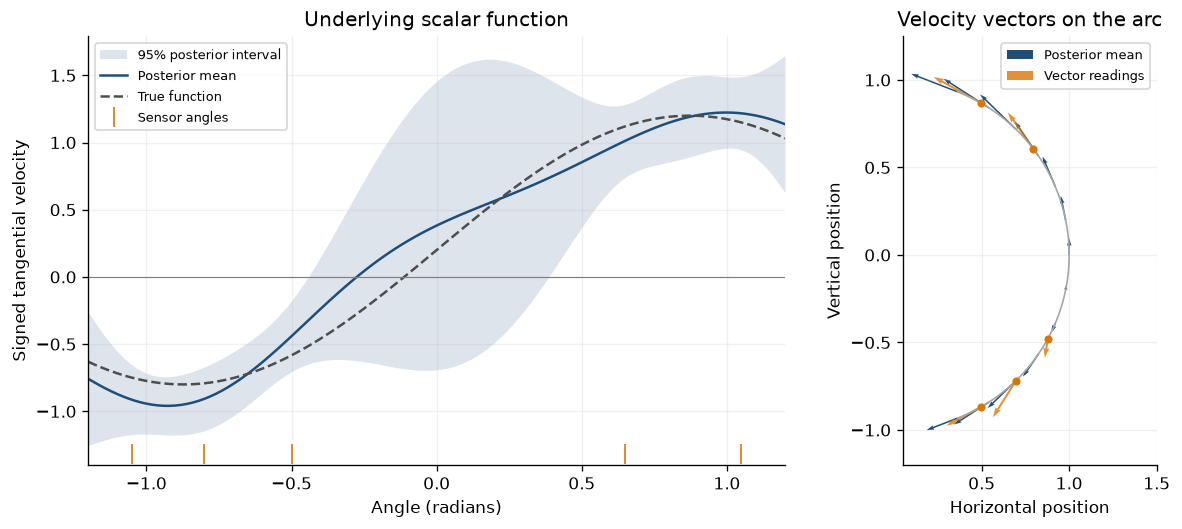

In [8]:
fig, axes = plt.subplots(
    1, 2, figsize=(10.5, 4.3),
    gridspec_kw={"width_ratios": [1.5, 1]}, layout="constrained",
)

mean = amplitude_posterior.mean["amplitude"]
sd = jnp.sqrt(amplitude_posterior.variance["amplitude"])
axes[0].fill_between(
    theta_plot, mean - 1.96 * sd, mean + 1.96 * sd,
    color="#1F4E79", alpha=0.15, linewidth=0,
    label="95% posterior interval",
)
axes[0].plot(theta_plot, mean, color="#1F4E79", label="Posterior mean")
axes[0].plot(
    theta_plot, jax.vmap(true_amplitude)(theta_plot[:, None]),
    color="0.3", linestyle="--", label="True function",
)
axes[0].plot(
    theta_observed, jnp.full_like(theta_observed, 0.025),
    marker="|", markersize=12, linestyle="none", color="#D97706",
    transform=axes[0].get_xaxis_transform(), label="Sensor angles",
)
axes[0].axhline(0.0, color="0.5", linewidth=0.7)
axes[0].set(
    title="Underlying scalar function", xlabel="Angle (radians)",
    ylabel="Signed tangential velocity", xlim=(-1.2, 1.2),
)
axes[0].legend(fontsize=8, loc="upper left")

arc = arc_points(theta_plot)
arrow_locations = arc_points(theta_arrows)
sensor_locations = arc_points(theta_observed)
axes[1].plot(arc[:, 0], arc[:, 1], color="0.65", linewidth=1)
axes[1].quiver(
    arrow_locations[:, 0], arrow_locations[:, 1],
    vector_mean[:, 0], vector_mean[:, 1],
    color="#1F4E79", angles="xy", scale_units="xy", scale=4,
    width=0.006, label="Posterior mean",
)
axes[1].quiver(
    sensor_locations[:, 0], sensor_locations[:, 1],
    readings[:, 0], readings[:, 1],
    color="#D97706", angles="xy", scale_units="xy", scale=4,
    width=0.008, alpha=0.8, label="Vector readings",
)
axes[1].scatter(
    sensor_locations[:, 0], sensor_locations[:, 1],
    color="#D97706", s=15, zorder=3,
)
axes[1].set(
    title="Velocity vectors on the arc", aspect="equal",
    xlabel="Horizontal position", ylabel="Vertical position",
    xlim=(0.05, 1.5), ylim=(-1.2, 1.25),
)
axes[1].legend(fontsize=8, loc="upper right")
plt.show()

The scalar uncertainty widens in the gap between sensors. Where the inferred
function changes sign, the vectors reverse their direction along the arc.
The noisy readings can point slightly away from the tangent, while every
predicted vector is constrained to lie along it. The two components come from
one scalar function and the known tangent.

The [custom-operator reference](../api/operators.md#custom-operators) describes
the interface for other linear measurements.